# Энергопотребление зданий (BDG2): малый ранг, мягкий малый ранг и латентные факторы

Данные Building Data Genome Project 2 (Miller и др., 2020): почасовые показания счётчиков 1636 зданий на 19 площадках (университеты, офисы, общественные здания) за 2016–2017 годы и погода каждой площадки. Лицензия CC BY-SA 4.0.

- **индивид** — счётчик электроэнергии здания;
- **время** — день (731 день);
- **отклик** — логарифм дневного потребления;
- **признаки** — погода площадки: температура и изломы по её квартилям, суточный размах, точка росы, ветер, вчерашняя и недельная температура, ветер в холод ($d=10$);
- **латентные факторы** — недельный цикл, праздники, учебный календарь: общие для многих зданий и не наблюдаемые напрямую.

Почему этот набор подходит для проверки: признаки различаются между площадками, зданий много, они разных типов (учебные, офисы, общежития), так что можно ждать «почти малого ранга» реакций на погоду с индивидуальными отклонениями. Длинный ряд позволяет учить модели на коротком отрезке, где малый ранг важен, и проверять на другом году.

**Как получить данные.** Скачать из репозитория `buds-lab/building-data-genome-project-2` (или с Zenodo, DOI 10.5281/zenodo.3887306) файлы `data/meters/cleaned/electricity_cleaned.csv`, `data/weather/weather.csv`, `data/metadata/metadata.csv` и положить в папку `raw/` рядом с ноутбуком.

In [1]:
import time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import panelfast as pf

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Дневная панель и очистка

День засчитывается, если есть не меньше 23 часов показаний; берём счётчики, у которых наблюдено не меньше 97% дней и медианное потребление не меньше 10 кВт·ч в день. Облачность, осадки и давление есть не на всех площадках, поэтому из погоды берём температуру, точку росы и ветер. Изломы температуры ставим по квартилям температуры своей площадки: климат площадок очень разный (от −12 до +37 °C), и с общими порогами часть признаков на некоторых площадках не менялась бы вовсе.

Очистка: (1) исключаются счётчики, у которых медианный уровень в 2017 году отличается от 2016-го больше чем в $e$ раз — в основном площадка Lamb, где в 2017 году сменились единицы; (2) дни, когда показание отличается от медианы здания больше чем в 10 раз (отключения, сбои), считаются пропусками. Без этого RMSE на 2017 годе определяют несколько сломанных счётчиков: 1.8% клеток дают больше 80% квадрата ошибки.

In [2]:
E = pd.read_csv('raw/electricity_cleaned.csv', parse_dates=['timestamp'])
day = E.timestamp.dt.floor('D'); E = E.drop(columns='timestamp')
cnt = E.groupby(day).count(); daily = E.groupby(day).sum(min_count=1).where(cnt >= 23)
daily = daily.where(daily > 0)
W = pd.read_csv('raw/weather.csv', parse_dates=['timestamp']); W['date'] = W.timestamp.dt.floor('D')
Wd = W.groupby(['site_id', 'date']).agg(t=('airTemperature', 'mean'), tmax=('airTemperature', 'max'), tmin=('airTemperature', 'min'),
                                        dew=('dewTemperature', 'mean'), wind=('windSpeed', 'mean')).reset_index()
meta = pd.read_csv('raw/metadata.csv').set_index('building_id')

obs = daily.notna().mean(); cols = list(obs[obs >= 0.97].index)
med = daily[cols].median(); cols = [c for c in cols if med[c] >= 10]
dates = daily.index; T = len(dates)
Y = np.log(daily[cols].values.T); MASK = np.isfinite(Y); Y = np.where(MASK, Y, 0.0)
SITES = np.array([c.split('_')[0] for c in cols]); TYPES = meta.loc[cols, 'primaryspaceusage'].fillna('Other').values
FEATS = ['t', '(t-q25)+', '(t-q50)+', '(t-q75)+', 'размах', 'точка росы', 'ветер', 't вчера', 't за неделю', 'ветер*(q50-t)+']
feat = {}
for s in np.unique(SITES):
    w = Wd[Wd.site_id == s].drop(columns='site_id').set_index('date').reindex(dates).interpolate(limit_direction='both')
    t = w.t.values; q25, q50, q75 = np.quantile(t, [0.25, 0.5, 0.75])
    feat[s] = np.column_stack([t, np.maximum(t - q25, 0), np.maximum(t - q50, 0), np.maximum(t - q75, 0), w.tmax.values - w.tmin.values,
                               w.dew.values, w.wind.values, np.r_[t[0], t[:-1]], pd.Series(t).rolling(7, min_periods=1).mean().values,
                               w.wind.values * np.maximum(q50 - t, 0)])
X = np.stack([feat[s] for s in SITES])

# очистка 1: счётчики с разрывом уровня между годами больше чем в e раз (на площадке Lamb в 2017 году сменились единицы)
y16 = dates < pd.Timestamp('2017-01-01')
medy = lambda A, m: np.array([np.median(a[mm]) for a, mm in zip(A, m)])
SHIFT = medy(Y[:, ~y16], MASK[:, ~y16]) - medy(Y[:, y16], MASK[:, y16])
KEEP = np.abs(SHIFT) <= 1.0
print('исключено счётчиков с разрывом уровня:', int((~KEEP).sum()), '| из них на площадке Lamb:', int(np.sum(~KEEP & (SITES == 'Lamb'))))
Y, X, MASK, SITES, TYPES = Y[KEEP], X[KEEP], MASK[KEEP], SITES[KEEP], TYPES[KEEP]
# очистка 2: аномальные дни (отключения, сбои) — показание отличается от медианы здания больше чем в 10 раз
mb = np.array([np.median(y[m]) for y, m in zip(Y, MASK)])
ANOM = MASK & (np.abs(Y - mb[:, None]) > np.log(10)); MASK = MASK & ~ANOM
print(f'аномальных дней помечено пропусками: {ANOM.sum()} ({ANOM.sum() / (MASK.sum() + ANOM.sum()):.2%} клеток)')
X = (X - X.reshape(-1, X.shape[2]).mean(0)) / X.reshape(-1, X.shape[2]).std(0)      # признаки в единицах ст. откл.
N, T, d = X.shape
DATES = dates.values.astype('datetime64[D]')
POOL = np.where(DATES < np.datetime64('2017-01-01'))[0]; TEST = np.where(DATES >= np.datetime64('2017-01-01'))[0]
print(f'n = {N} счётчиков на {len(np.unique(SITES))} площадках, T = {T} дней, d = {d}, наблюдено {MASK.mean():.1%} клеток')
pd.Series(TYPES).value_counts().head(6)

исключено счётчиков с разрывом уровня: 59 | из них на площадке Lamb: 46
аномальных дней помечено пропусками: 5754 (1.04% клеток)
n = 758 счётчиков на 12 площадках, T = 731 дней, d = 10, наблюдено 98.4% клеток


Education                        292
Office                           157
Public services                  100
Entertainment/public assembly     80
Lodging/residential               60
Healthcare                        17
Name: count, dtype: int64

## 2. Видны ли факторы и малый ранг

Сингулярные числа матрицы остатков после регрессии по каждому зданию без факторов (2016 год) и матрицы наклонов, оценённых МНК по каждому зданию с тремя факторами.

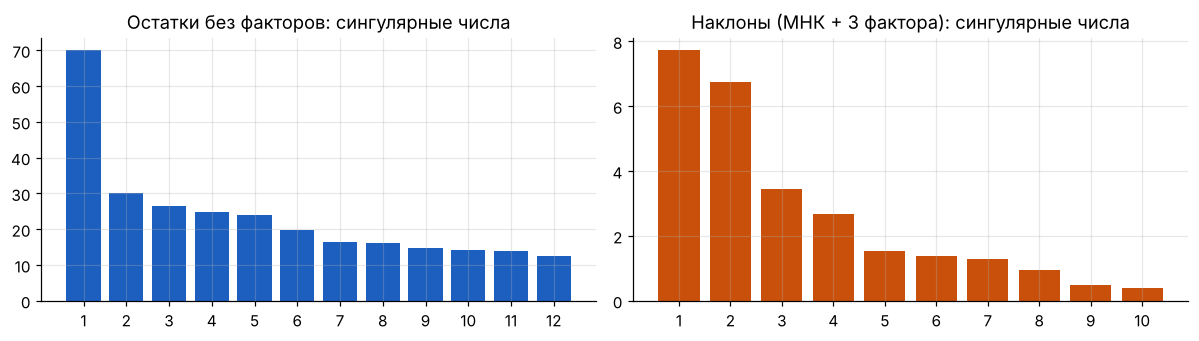

остатки: [70.  30.2 26.6 24.8 24.  19.8 16.4 16.3]
наклоны: [7.72 6.73 3.44 2.69 1.53 1.37 1.29 0.96 0.48 0.4 ]


In [3]:
d16 = POOL
G, Z, _, _ = pf.unit_stats(X[:, d16], Y[:, d16], MASK[:, d16], None); B0 = pf.solve(G, Z)
R = pf.residuals(Y[:, d16], X[:, d16], B0); c0 = np.where(MASK[:, d16], R, 0).sum(1) / MASK[:, d16].sum(1)
s_res = np.linalg.svd(np.where(MASK[:, d16], R - c0[:, None], 0), compute_uv=False)
H3 = pf.fit(Y[:, d16], X[:, d16], MASK[:, d16], d, 3, tol=1e-6)
s_B = np.linalg.svd(H3['B'], compute_uv=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
axs[0].bar(np.arange(1, 13), s_res[:12], color='#1d5fbf'); axs[0].set_title('Остатки без факторов: сингулярные числа'); axs[0].set_xticks(np.arange(1, 13))
axs[1].bar(np.arange(1, d + 1), s_B, color='#c8500a'); axs[1].set_title('Наклоны (МНК + 3 фактора): сингулярные числа'); axs[1].set_xticks(np.arange(1, d + 1))
plt.tight_layout(); plt.show()
print('остатки:', np.round(s_res[:8], 1)); print('наклоны:', np.round(s_B, 2))

В остатках один фактор очень сильный (сингулярное число 70), за ним идут несколько заметных (30, 27, 25, 24, …): недельный цикл, праздники и календари площадок. Сингулярные числа наклонов убывают плавно (7.7, 6.7, 3.4, 2.7, 1.5, …). Точного малого ранга нет, ранг «почти малый» — ровно ситуация мягкого малого ранга.

## 3. Выбор чисел индексов и факторов

Обучение на 120 случайных днях 2016 года, валидация на остальных днях 2016 года: здания делятся пополам, факторы дня оцениваются по одной половине, отклик предсказывается для другой. Сетка: $m\in\{1,2,3,4,10\}$ ($m=10$ — МНК по каждому зданию), $r\in\{2,4,6,8,10\}$; для конкурентов с общими наклонами и с наклонами по типу здания — те же $r$.

In [4]:
TOL = 1e-6

def fit_spec(spec, days):
    kind, m, r = spec
    Yt, Xt, mt = Y[:, days], X[:, days], MASK[:, days]
    if kind == 'twoway': return pf.fit_twoway(Yt, Xt, mt)
    if kind in ('common', 'group'): return pf.fit(Yt, Xt, mt, 0, r, kind=kind, groups=TYPES, tol=TOL)
    H = pf.fit(Yt, Xt, mt, m, r, tol=TOL)
    if kind == 'lr': return H
    return pf.fit_soft(Yt, Xt, mt, m, r, {'soft_eb': 'eb', 'soft_split': 'split'}[kind], hard=H, tol=TOL)

def predict(M, days, oc):
    Xd, Yd = X[:, days], Y[:, days]
    base = np.einsum('itd,id->it', Xd, M['B']) + M['c'][:, None]; R = Yd - base; comp = np.zeros_like(base)
    for j in range(len(days)):
        o = oc[:, j]
        if M.get('kind') == 'twoway': comp[:, j] = R[o, j].mean()
        elif M['G'].shape[1]: comp[:, j] = M['G'] @ np.linalg.lstsq(M['G'][o], R[o, j], rcond=None)[0]
    return base + comp

def evaluate(models, days, nsplit, rng):
    out = {k: [] for k in models}
    for _ in range(nsplit):
        held = rng.random(N) < 0.5
        tc, oc = MASK[:, days] & held[:, None], MASK[:, days] & ~held[:, None]
        for k, M in models.items():
            out[k].append(float(np.sqrt(np.mean((Y[:, days] - predict(M, days, oc))[tc] ** 2))))
    return {k: float(np.mean(v)) for k, v in out.items()}

t0 = time.time()
rng = np.random.default_rng(42)
tr = np.sort(rng.choice(POOL, 120, replace=False)); va = np.setdiff1d(POOL, tr)
grid = {f'm{m}_r{r}': ('lr', m, r) for m in (1, 2, 3, 4, 10) for r in (2, 4, 6, 8, 10)}
grid.update({f'common_r{r}': ('common', 0, r) for r in (2, 4, 6, 8, 10)})
grid.update({f'group_r{r}': ('group', 0, r) for r in (2, 4, 6, 8, 10)})
val = evaluate({k: fit_spec(s, tr) for k, s in grid.items()}, va, 3, rng)
print(f'время: {time.time() - t0:.0f} с')
V = pd.DataFrame([[m] + [val[f'm{m}_r{r}'] for r in (2, 4, 6, 8, 10)] for m in (1, 2, 3, 4, 10)], columns=['m', 'r=2', 'r=4', 'r=6', 'r=8', 'r=10']).set_index('m')
V.loc['общие'] = [val[f'common_r{r}'] for r in (2, 4, 6, 8, 10)]; V.loc['по типу'] = [val[f'group_r{r}'] for r in (2, 4, 6, 8, 10)]
best = min([k for k in val if k.startswith('m') and not k.startswith('m10')], key=val.get)
pick = lambda pre: min([k for k in val if k.startswith(pre)], key=val.get)
m_b, r_b = grid[best][1], grid[best][2]
print('выбор:', best, '| МНК:', pick('m10'), '| общие:', pick('common'), '| по типу:', pick('group'))
V.round(4)

время: 165 с
выбор: m1_r10 | МНК: m10_r6 | общие: common_r10 | по типу: group_r10


,r=2,r=4,r=6,r=8,r=10
m,,,,,
1,0.1851,0.1701,0.1592,0.1542,0.1521
2,0.1793,0.1656,0.1563,0.1687,0.1571
3,0.1795,0.1656,0.1560,0.1873,0.1626
4,0.1789,0.1654,0.1557,0.1845,0.1648
10,0.1815,0.1690,0.1578,0.1605,0.1640
общие,0.2010,0.1773,0.1636,0.1579,0.1534
по типу,0.1992,0.1772,0.1639,0.1579,0.1535


## 4. Проверка на 2017 годе при разной длине обучения

Модели учатся на $T\in\{40, 80, 160, 366\}$ случайных днях 2016 года (366 — весь год), а проверяются на всём 2017 годе: здания делятся пополам (10 разбиений), факторы дня оцениваются по известной половине, отклик предсказывается для другой. Числа $m$ и $r$ — из раздела 3. Мягкая оценка берёт те же $m$ и $r$, а $\kappa$ находит сама: эмпирическим Байесом или по двум половинам обучающих дней.

По части (c) теоремы при малом $T$ должна выигрывать жёсткая оценка, при большом — догонять МНК, а мягкая — быть не хуже лучшей из них.

In [5]:
final = {'МНК + факторы': grid[pick('m10')], 'двусторонние эффекты': ('twoway', 0, 0), 'общие наклоны + факторы': grid[pick('common')],
         'наклоны по типу здания + факторы': grid[pick('group')], 'жёсткая': ('lr', m_b, r_b),
         'мягкая (ЭБ)': ('soft_eb', m_b, r_b), 'мягкая (половины)': ('soft_split', m_b, r_b)}
res, info, fitted = {}, {}, {}
t0 = time.time()
for Tn in (40, 80, 160, 366):
    days = POOL if Tn == 366 else np.sort(np.random.default_rng(Tn).choice(POOL, Tn, replace=False))
    M = {k: fit_spec(s, days) for k, s in final.items()}
    res[Tn] = evaluate(M, TEST, 10, np.random.default_rng(100 + Tn))
    S, Sp = M['мягкая (ЭБ)'], M['мягкая (половины)']
    info[Tn] = dict(kappa_eb=S['kappa'], tau2_eb=S['tau2'], share=S['share'], kappa_split=Sp['kappa'], tau2_split=Sp['tau2_split'])
    fitted[Tn] = M
print(f'время: {time.time() - t0:.0f} с')
tab = pd.DataFrame(res).T; tab.index.name = 'T обучения'
print('RMSE логарифма дневного потребления отложенных зданий в 2017 году')
tab.round(4)

время: 349 с
RMSE логарифма дневного потребления отложенных зданий в 2017 году


,МНК + факторы,двусторонние эффекты,общие наклоны + факторы,наклоны по типу здания + факторы,жёсткая,мягкая (ЭБ),мягкая (половины)
T обучения,,,,,,,
40,0.2858,0.3035,0.2599,0.2784,0.2589,0.2589,0.2589
80,0.2576,0.2812,0.2528,0.2524,0.2578,0.2578,0.2601
160,0.2458,0.2700,0.2472,0.2470,0.2468,0.2468,0.2476
366,0.2369,0.2630,0.2391,0.2391,0.2421,0.2453,0.2455


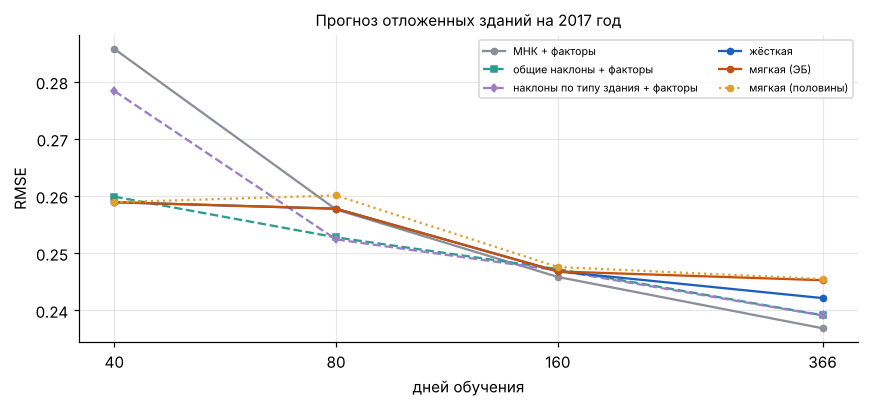

Мягкая оценка: kappa и tau^2 эмпирическим Байесом и по двум половинам ряда


,kappa_eb,tau2_eb,share,kappa_split,tau2_split
T обучения,,,,,
40,inf,0.0000,0.0000,inf,0.0000
80,inf,0.0000,0.0000,3.3301,0.0041
160,inf,0.0000,0.0000,7.2754,0.0020
366,3.5633,0.0043,0.6644,5.6730,0.0027


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sty = {'МНК + факторы': ('#8a8f98', 'o-'), 'общие наклоны + факторы': ('#2a9d8f', 's--'), 'наклоны по типу здания + факторы': ('#9b7fc4', 'd--'),
       'жёсткая': ('#1d5fbf', 'o-'), 'мягкая (ЭБ)': ('#c8500a', 'o-'), 'мягкая (половины)': ('#e0a030', 'o:')}
for k, (c, ls) in sty.items():
    ax.plot(tab.index, tab[k], ls, color=c, ms=4, label=k)
ax.set_xscale('log'); ax.minorticks_off(); ax.set_xticks(tab.index); ax.set_xticklabels(tab.index)
ax.set_xlabel('дней обучения'); ax.set_ylabel('RMSE'); ax.legend(fontsize=7, ncol=2)
ax.set_title('Прогноз отложенных зданий на 2017 год', fontsize=10)
plt.tight_layout(); plt.show()
D = pd.DataFrame(info).T; D.index.name = 'T обучения'
print('Мягкая оценка: kappa и tau^2 эмпирическим Байесом и по двум половинам ряда')
D.round(4)

- **Компромисс по $T$ виден.** На 40 днях жёсткая оценка (0.259) и общие наклоны (0.260) заметно лучше МНК по каждому зданию (0.286, разница 9%). На полном году лучше всех МНК (0.237 против 0.242 у жёсткой). Это ровно предсказание части (c) теоремы: дисперсия МНК убывает как $1/T$, а смещение малого ранга от $T$ не зависит. Оговорка: МНК выбрал $r=6$, жёсткая и мягкая оценки — $r=10$, так что часть разницы на полном году связана с числом факторов.
- **Малый ранг против общих наклонов.** На валидации малый ранг ($m=1$) чуть лучше общих наклонов (0.152 против 0.153). На 2017 годе при 40 днях они вничью, при 80 и 366 днях малый ранг на 1–2% хуже. Разнородность реакции на погоду есть, но по сравнению с шумом дня и факторной частью она мала.
- **Мягкая оценка прогноз не улучшает.** При 40–160 днях эмпирический Байес не находит отклонений ($\hat\kappa=\infty$), и мягкая оценка совпадает с жёсткой; на 40 днях это лучший результат. На полном году отклонения находятся (доля 0.66), но мягкая оценка (0.245) хуже и жёсткой (0.242), и МНК (0.237). Оценка по половинам ряда даёт малые $\tau^2$ и почти тот же результат.

## 5. Что означают индексы

Веса признаков в индексах (строки $P$) и нагрузки зданий $\ell_i$ на первый индекс по типам зданий для жёсткой оценки, обученной на всём 2016 годе.

/tmp/ipykernel_1494/1315778952.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[1].boxplot([L[TYPES == tp, 0] for tp in top], vert=False, flierprops=dict(markersize=3))


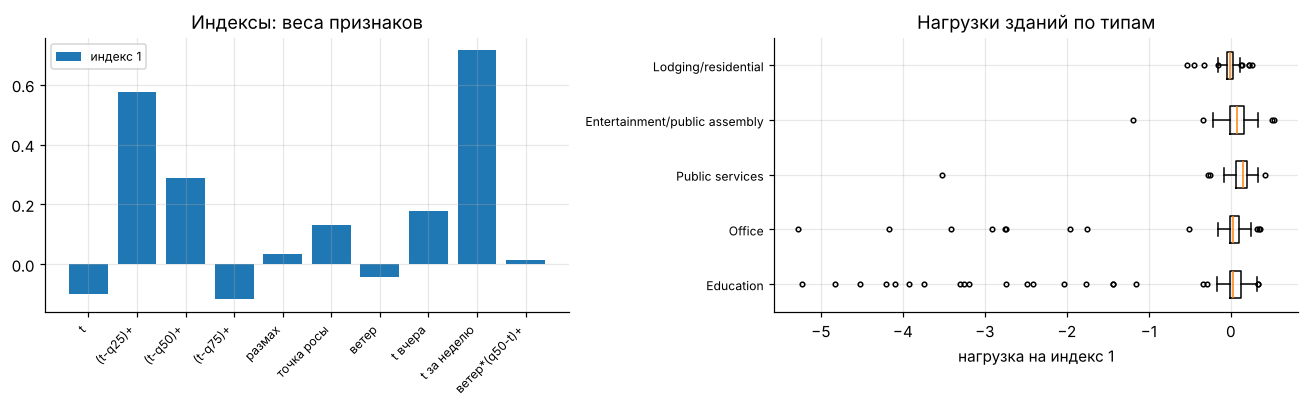

In [7]:
H = fitted[366]['жёсткая']
P = H['P']; L = H['B'] @ P.T
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.8 / P.shape[0]
for j in range(P.shape[0]):
    axs[0].bar(np.arange(d) + (j - (P.shape[0] - 1) / 2) * w, P[j], width=w, label=f'индекс {j + 1}')
axs[0].set_xticks(np.arange(d)); axs[0].set_xticklabels(FEATS, rotation=45, ha='right', fontsize=8); axs[0].legend(fontsize=8); axs[0].set_title('Индексы: веса признаков')
top = list(pd.Series(TYPES).value_counts().index[:5])
axs[1].boxplot([L[TYPES == tp, 0] for tp in top], vert=False, flierprops=dict(markersize=3))
axs[1].set_yticks(range(1, len(top) + 1)); axs[1].set_yticklabels(top, fontsize=8)
axs[1].set_xlabel('нагрузка на индекс 1'); axs[1].set_title('Нагрузки зданий по типам')
plt.tight_layout(); plt.show()

Единственный индекс в основном нагружен на тёплую часть температурной шкалы и на температуру за неделю, то есть описывает чувствительность к теплу. У большинства зданий нагрузка около нуля, а у части учебных и офисных она большая отрицательная: в тёплые недели их потребление падает. Скорее всего, это летние каникулы — календарь своей площадки, который общие для всех зданий факторы не улавливают, а индекс не может отделить от погоды.

## Итоги

1. **Данные подходят по формальным критериям**, но их пришлось чистить: на одной площадке в 2017 году сменились единицы, около 1% дней — сбои. После очистки ошибку прогноза в основном составляют шум дня и факторная часть (недельный цикл, календари).
2. **Компромисс по длине обучения подтверждается:** при 40 днях ограничение разнородности выигрывает у МНК по каждому зданию 9%, при годе выигрывает МНК.
3. **Малый ранг не лучше общих наклонов, мягкая оценка прогноз не улучшает.** Автоматический выбор $\kappa$ на коротких рядах правильно сводит её к жёсткой оценке, а на полном году не помогает.
4. **Вывод:** мягкий малый ранг — теоретически обоснованное обобщение и полезная проверка предположения о точном малом ранге, но данных, где он даёт заметный выигрыш, мы пока не нашли.